## image-to-coco-json-converter

- This code transforms segmentation mask images to annotation JSON files as per the MS COCO format http://cocodataset.org/#format-data
- https://github.com/chrise96/image-to-coco-json-converter/tree/master?tab=readme-ov-file
- https://www.immersivelimit.com/tutorials/create-coco-annotations-from-scratch

- 2024 0ctober 12 understood and verified JS

create_sub_mask_annotation() は MultiPolygon を直接返すようにする

images_annotations_info() 側は既存の if category_id in multipolygon_ids: の分岐を活かす

In [1]:
import importlib

In [2]:
import glob

from src.create_annotations import *

im_size = 512    ################ This is important. you have to decide the size to crop.


# Label ids of the dataset
category_ids = {
    "stuff" : 0,
    "vessel": 1,
    "ray": 2,
    "fiber": 3,
    "parenchyma": 4
}

# Define which colors match which categories in the images
category_colors = {
    "(255, 255, 255)": 1, # uco
    "(191, 191, 191)": 2, # ray
    "(127, 127, 127)": 3, # fiber
    "(63, 63, 63)": 4, # parenchyma
    "(0, 0, 0)": 0 # stuff
}

# # Label ids of the dataset
# category_ids = {
#     "stuff" : 0,
#     "unknown": 1,
# }

# # Define which colors match which categories in the images
# category_colors = {
#     "(255, 255, 255)": 1, # unknown
#     "(0, 0, 0)": 0 # stuff
# }
# Define the ids that are a multiplolygon. In our case: wall, roof and sky
multipolygon_ids = []

# Get "images" and "annotations" info 
def images_annotations_info(maskpath):
    # This id will be automatically increased as we go
    annotation_id = 0
    image_id = 0
    annotations = []
    images = []
    
    for mask_image in glob.glob(maskpath + "*.png"):
        # The mask image is *.png but the original image is *.jpg.
        # We make a reference to the original file in the COCO JSON file
        original_file_name = os.path.basename(mask_image).split(".")[0] + ".png"

        # Open the image and (to be sure) we convert it to RGB
        mask_image_open = Image.open(mask_image).convert("RGB")
        w, h = mask_image_open.size
        print(np.unique(np.array(mask_image_open).flatten()))
        # "images" info 
        image = create_image_annotation(original_file_name, w, h, image_id)
        images.append(image)

        sub_masks = create_sub_masks(mask_image_open, w, h)
        
        for color, sub_mask in sub_masks.items():
            category_id = category_colors[color]

            # "annotations" info
            polygons, segmentations = create_sub_mask_annotation(sub_mask)

            # Check if we have classes that are a multipolygon
            if category_id in multipolygon_ids:
                # Combine the polygons to calculate the bounding box and area
                multi_poly = MultiPolygon(polygons)
                                
                annotation = create_annotation_format(multi_poly, segmentations, image_id, category_id, annotation_id)

                annotations.append(annotation)
                annotation_id += 1
            else:
                for i in range(len(polygons)):
                    # Cleaner to recalculate this variable
                    segmentation = [np.array(polygons[i].exterior.coords).ravel().tolist()]
                    
                    annotation = create_annotation_format(polygons[i], segmentation, image_id, category_id, annotation_id)
                    
                    annotations.append(annotation)
                    annotation_id += 1
        image_id += 1
        # print(image_id)
    return images, annotations, annotation_id

if __name__ == "__main__":
    # Get the standard COCO JSON format
    coco_format = get_coco_json_format()
    

    
    for keyword in ["test", "valid", "train"]:
        mask_path = "dataset/png_"+str(im_size)+"/mask/{}/".format(keyword)

        coco_format["info"] = info()
        # Create category section
        coco_format["categories"] = create_category_annotation(category_ids)
    
        # Create images and annotations sections
        coco_format["images"], coco_format["annotations"], annotation_cnt = images_annotations_info(mask_path)

        with open("dataset/png_"+str(im_size)+"/image/{}".format(keyword)+\
                  "/{}_annot_coco_".format(keyword)+str(im_size)+".json","w") as outfile:
            json.dump(coco_format, outfile)
        
        print("Created %d annotations for images in folder: %s" % (annotation_cnt, mask_path))


[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 1

loading annotations into memory...
Done (t=0.10s)
creating index...
index created!
loading annotations into memory...
Done (t=0.12s)
creating index...
index created!
loading annotations into memory...
Done (t=0.18s)
creating index...
index created!


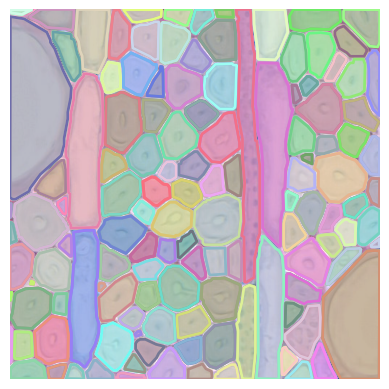

[{'file_name': '0004_exostr1_02_img.png',
  'height': 512,
  'width': 512,
  'id': 2,
  'date_captured': '2025 Izumi '}]

In [3]:
## call Coco tool
from pycocotools.coco import COCO
import matplotlib.pyplot as plt

# read annotation json file
anno_path = "dataset/png_"+str(im_size)+"/image/train/train_annot_coco_"+str(im_size)+".json"
coco_cap = COCO(anno_path)
coco_ins = COCO(anno_path)
coco_key = COCO(anno_path)

# select image ID to visualize
img_id = coco_cap.getImgIds()[2]
img_info = coco_cap.loadImgs(img_id)
img_path = "./dataset/png_"+str(im_size)+f"/image/train/{img_info[0]['file_name']}"

# obtain annotation indices of the corresponding image
anno_ids_cap = coco_cap.getAnnIds(img_id)
anno_ids_ins = coco_ins.getAnnIds(img_id)
anno_ids_key = coco_key.getAnnIds(img_id)

# obtain annotation data from the indices
annos_cap = coco_cap.loadAnns(anno_ids_cap)
annos_ins = coco_ins.loadAnns(anno_ids_ins)
annos_key = coco_key.loadAnns(anno_ids_key)

# drew annotation polygons on the image
img = plt.imread("./dataset/png_"+str(im_size)+f"/image/train/{img_info[0]['file_name']}")
plt.imshow(img)
coco_cap.showAnns(annos_cap)
coco_ins.showAnns(annos_ins)
coco_key.showAnns(annos_key)
plt.axis('off')
plt.show()
coco_cap.loadImgs(2)

The end of script.